In [4]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

df = pd.read_csv("data/train_starter_2000.csv")
X = np.load("data/starter_embeddings.npy")
y = df["label"]


X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=20261023,
    stratify=y
)


# Hyperparameter Tuning
best_auc = 0
best_smoothing = None
best_model = None

for smoothing in [1e-9, 1e-8, 1e-7, 1e-6]:

    model = GaussianNB(var_smoothing=smoothing)

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    train_prob = model.predict_proba(X_train)[:, 1]
    val_prob = model.predict_proba(X_val)[:, 1]

    train_auc = roc_auc_score(y_train, train_prob)
    val_auc = roc_auc_score(y_val, val_prob)

    print("var_smoothing:", smoothing)
    print("Training ROC-AUC:", train_auc)
    print("Validation ROC-AUC:", val_auc)
    print("Training Time:", round(train_time, 4), "seconds")
    print()

    if val_auc > best_auc:
        best_auc = val_auc
        best_smoothing = smoothing
        best_model = model


# Evaluate
y_pred = best_model.predict(X_val)

print("Training size:", len(X_train))
print("Validation size:", len(X_val))
print("Best var_smoothing:", best_smoothing)
print("Best Validation ROC-AUC:", best_auc)
print("Best Validation Accuracy:", accuracy_score(y_val, y_pred))
print("Best Validation F1 Score:", f1_score(y_val, y_pred))


var_smoothing: 1e-09
Training ROC-AUC: 0.9021203125
Validation ROC-AUC: 0.855675
Training Time: 0.1276 seconds

var_smoothing: 1e-08
Training ROC-AUC: 0.9021203125
Validation ROC-AUC: 0.855675
Training Time: 0.027 seconds

var_smoothing: 1e-07
Training ROC-AUC: 0.9021203125
Validation ROC-AUC: 0.855675
Training Time: 0.0043 seconds

var_smoothing: 1e-06
Training ROC-AUC: 0.902121875
Validation ROC-AUC: 0.855675
Training Time: 0.0127 seconds

Training size: 1600
Validation size: 400
Best var_smoothing: 1e-09
Best Validation ROC-AUC: 0.855675
Best Validation Accuracy: 0.755
Best Validation F1 Score: 0.7574257425742573


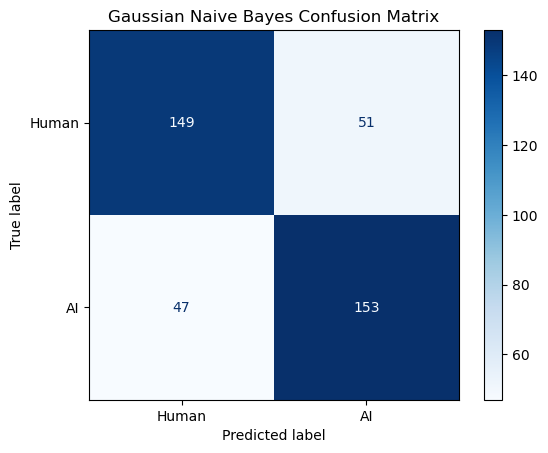

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["Human", "AI"],
    cmap="Blues"
)

plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()